<div style="background: linear-gradient(135deg, #1e50a0 0%, #2e6cc0 100%); padding: 36px 40px; border-radius: 10px; color: white; margin-bottom: 20px;">
    <h1 style="color: white; margin: 0 0 8px 0; font-size: 2em;">Introduction to Deep Learning | MNIST Case</h1>
    <h2 style="color: #c8dcff; margin: 0 0 12px 0; font-weight: normal; font-size: 1.3em;">Multi-Layer Perceptron from Scratch in NumPy</h2>
    <p style="color: #a0bce0; margin: 0; font-size: 1em;">Forward pass &nbsp;·&nbsp; Back-propagation by hand &nbsp;·&nbsp; SGD / mini-batch / Adam &nbsp;·&nbsp; Dropout &nbsp;·&nbsp; Gradient check &nbsp;·&nbsp; NumPy only</p>
    <hr>
    <p style="color: #a0bce0; margin: 0; font-size: 1em;">Author: A.S.Grm (aleksander.grm@fpp.uni-lj.si), 2026</p>
</div>

## 1. Introduction

### 1.1 The task

The **MNIST** data set (LeCun et al., 1998) contains $70\,000$ grey-scale images of hand-written digits
$0,1,\dots,9$, each $28\times28$ pixels:

| Split | Images | Use in this notebook |
|---|---:|---|
| training set | 60 000 | weights are fitted here (we often use only a small subset) |
| test set | 10 000 | measured **once**, at the very end, to estimate performance on unseen data |

Each pixel is an integer in $[0,255]$ (0 = black background, 255 = white ink). The goal is a function

$$f_\theta:\ \mathbb R^{784} \to \mathbb R^{10},\qquad \hat k = \arg\max_c f_\theta(x)_c ,$$

that maps a flattened image $x$ to ten class scores and predicts the digit $\hat k$ with the largest score.
$\theta$ denotes all trainable weights and biases. We use the simplest deep-learning model that solves the
task well: the **multi-layer perceptron (MLP)**, also called a fully-connected feed-forward network.

### 1.2 How this notebook is built

Every piece of the network is written by hand with **NumPy only**: the forward pass, the loss, the back-propagation of gradients, dropout, and the optimisers (SGD, momentum, Adam). Nothing is hidden, so you can see every multiplication that a deep-learning framework normally does for you.

There is a twin notebook that implements **exactly the same experiments in PyTorch**. The section
numbers, the hyper-parameters and the loss definitions are identical, so the two notebooks can be read
side by side and their results compared directly.

The notebook combines four earlier codes into one consistent story:

| Earlier code | What it contained | Where it is now |
|---|---|---|
| `chapter_8_1` | one-image-at-a-time SGD, with and without dropout (Trask, ch. 8) | Experiment A |
| `chapter_8_2_batch` | mini-batch SGD: a naive (wrong) and a vectorised version | Theory 2.7 + Experiment B |
| `chapter_8_3_..._primer` | PyTorch MLP on the GPU, mini-batches | model / training-loop design |
| `chapter_8_3_..._master` | train / validation / test split, checkpoint selection, dropout ON vs OFF over 5 seeds | Experiment C |
| *new* | modern set-up: full MNIST, biases, He initialisation, softmax + cross-entropy, Adam | Experiment D |

### 1.3 Roadmap

| Section | Content |
|---|---|
| 2 | Theory: neuron, MLP, activation, loss, gradient descent, back-propagation, mini-batches, initialisation, dropout, optimisers, data splits |
| 3 | Imports, reproducibility |
| 4 | Loading and preparing MNIST |
| 5 | The building blocks: the MLP, the losses, the optimisers, the training loop |
| 6 | Gradient check: is the back-propagation correct? |
| 7 | **Experiment A** – stochastic gradient descent (one image per step), dropout OFF / ON |
| 8 | **Experiment B** – mini-batch gradient descent |
| 9 | **Experiment C** – dropout ON vs OFF, 5 seeds, validation-based checkpoint selection |
| 10 | **Experiment D** – a modern MLP on the full 60 000 images |
| 11 | Analysis of the final model: confusion matrix, errors, learned features |
| 12 | Summary, exercises, references |

## 2. Theory

### 2.1 Learning as optimisation

Given $N$ training pairs $\{(x_i, y_i)\}_{i=1}^N$ we look for parameters $\theta$ that minimise the
**empirical risk** (average loss)

$$\mathcal L(\theta) = \frac1N\sum_{i=1}^{N} \ell\big(f_\theta(x_i),\,y_i\big).$$

What we really want is a small error on **unseen** images (generalisation). The empirical risk is only a
proxy; Sections 2.9 and 2.10 deal with the gap between the two.

### 2.2 Neuron, layer and network

A single **neuron** forms a weighted sum of its inputs and passes it through a non-linear **activation** $\sigma$:

$$z = \sum_j w_j x_j + b = w^\top x + b, \qquad a = \sigma(z).$$

A **layer** is many neurons that read the same input. For a mini-batch of $B$ samples stored as rows of a matrix
(the *row-vector convention* used by NumPy and PyTorch):

$$Z^{(l)} = A^{(l-1)}\,W^{(l)} + \mathbf 1\, b^{(l)}, \qquad A^{(l)} = \sigma\big(Z^{(l)}\big),\qquad A^{(0)} = X.$$

| Symbol | Shape | Meaning |
|---|---|---|
| $X = A^{(0)}$ | $(B, 784)$ | batch of flattened images |
| $W^{(l)}$ | $(n_{l-1}, n_l)$ | weights of layer $l$ |
| $b^{(l)}$ | $(n_l,)$ | biases of layer $l$ (broadcast over the batch) |
| $Z^{(l)}, A^{(l)}$ | $(B, n_l)$ | pre-activations and activations |
| $\hat Y = Z^{(L)}$ | $(B, 10)$ | output scores (no activation on the last layer, or softmax) |

In NumPy we store $W^{(l)}$ with shape $(n_{l-1}, n_l)$ – exactly as Trask does – so the layer is literally `A @ W + b`.

The network used in most experiments (identical to Trask, ch. 8, and to the earlier codes) is

$$\underbrace{784}_{\text{input}}\ \xrightarrow{\;W^{(1)}\;}\ \underbrace{100}_{\text{ReLU (+dropout)}}\ \xrightarrow{\;W^{(2)}\;}\ \underbrace{10}_{\text{scores}}$$

with $784\cdot100 + 100\cdot10 = 79\,400$ weights and no biases.

### 2.3 Activation function

Without a non-linearity a stack of layers collapses to a single linear map,
$X W^{(1)} W^{(2)} = X W$, and could only separate classes with hyperplanes.
We use the **rectified linear unit**

$$\mathrm{ReLU}(z) = \max(0, z), \qquad \mathrm{ReLU}'(z) = \begin{cases}1 & z>0\\ 0 & z\le 0\end{cases}$$

It is cheap, its derivative does not vanish for positive inputs (unlike sigmoid / tanh), and it produces sparse
activations. ($\mathrm{ReLU}'(0)$ is undefined; by convention we use 0.)

### 2.4 Output and loss function

The labels are **one-hot** encoded: digit $k$ becomes $y = e_k \in \{0,1\}^{10}$, e.g. $5 \to (0,0,0,0,0,1,0,0,0,0)$.

**(a) Mean squared error (MSE)** – used by Trask and in Experiments A–C. We define it per sample as half the
squared distance and average over the batch:

$$\mathcal L_\text{MSE} = \frac{1}{B}\sum_{i=1}^{B} \frac12\,\big\lVert \hat y_i - y_i \big\rVert^2
\quad\Longrightarrow\quad
\frac{\partial \mathcal L_\text{MSE}}{\partial \hat Y} = \frac{1}{B}\big(\hat Y - Y\big).$$

The factor $\tfrac12$ cancels the 2 of the derivative, so for $B=1$ the gradient is exactly Trask's
`layer_2_delta = labels - layer_2` (with the opposite sign, because Trask *adds* the update).
*Note:* `torch.nn.MSELoss(reduction="mean")` divides by $B\cdot C$ and has no $\tfrac12$, i.e.
$\mathcal L_\text{MSE} = \tfrac{C}{2}\,\texttt{MSELoss}$; the same step therefore needs a 5× larger learning rate with `MSELoss`.

**(b) Softmax + cross-entropy** – the standard choice for classification (Experiment D). Softmax turns scores into
probabilities, cross-entropy measures the negative log-probability of the correct class:

$$p_{ic} = \frac{e^{z_{ic}}}{\sum_{c'} e^{z_{ic'}}},\qquad
\mathcal L_\text{CE} = -\frac1B\sum_{i=1}^B\sum_{c=1}^{10} y_{ic}\log p_{ic}
\quad\Longrightarrow\quad
\frac{\partial \mathcal L_\text{CE}}{\partial Z} = \frac1B\big(P - Y\big).$$

The gradient has the same simple form "prediction minus target" as MSE, but the loss punishes confident wrong
answers much more strongly, which usually gives faster training and higher accuracy. For numerical stability the
maximum score is subtracted before exponentiation ($\mathrm{softmax}(z) = \mathrm{softmax}(z - \max z)$).

### 2.5 Gradient descent

The gradient $\nabla_\theta\mathcal L$ points in the direction of steepest increase of the loss, so we step the
other way:

$$\theta \leftarrow \theta - \eta\,\nabla_\theta \mathcal L .$$

The **learning rate** $\eta$ (Trask: `alpha`) sets the step size: too small – slow progress; too large – the loss
oscillates or diverges.

### 2.6 Back-propagation

Back-propagation is the chain rule applied layer by layer, from the output back to the input. Define the
**delta** of layer $l$ as the gradient of the loss with respect to its pre-activation,
$\delta^{(l)} = \partial\mathcal L / \partial Z^{(l)}$ (shape $(B, n_l)$). Then

$$
\boxed{
\begin{aligned}
\delta^{(L)} &= \tfrac1B(\hat Y - Y) && \text{(output, MSE or softmax-CE)}\\
\nabla_{W^{(l)}}\mathcal L &= A^{(l-1)\top}\,\delta^{(l)} && (n_{l-1}, n_l)\\
\nabla_{b^{(l)}}\mathcal L &= \textstyle\sum_{i} \delta^{(l)}_{i,:} && (n_l,)\\
\delta^{(l-1)} &= \big(\delta^{(l)}\,W^{(l)\top}\big) \odot \sigma'\big(Z^{(l-1)}\big) && (B, n_{l-1})
\end{aligned}
}
$$

$\odot$ is the element-wise product. One forward pass stores $A^{(l)}$ and $Z^{(l)}$; one backward pass then
delivers *all* gradients at roughly the cost of a second forward pass. This is what makes training networks with
millions of parameters possible. A **gradient check** (Section 6) compares these formulas with finite differences
or with automatic differentiation.

### 2.7 Stochastic, mini-batch and full-batch gradient descent

| Variant | Samples per step $B$ | Steps per epoch | Character |
|---|---|---|---|
| stochastic (SGD) | 1 | $N$ | very noisy, many cheap steps, poor use of vectorised hardware |
| mini-batch | 16 – 512 | $N/B$ | good compromise; standard in practice |
| full batch | $N$ | 1 | exact gradient, expensive steps, can get stuck in sharp minima |

An **epoch** is one pass through all training samples. Samples are **shuffled** every epoch so that consecutive
batches are not correlated.

**Learning-rate scaling.** With the *mean* loss the gradient does not grow with $B$; with a *summed* loss it grows
proportionally to $B$. The same step therefore needs $\eta_\text{mean} = B\,\eta_\text{sum}$. Trask's batch code
divides the delta by $B$ and multiplies the update by $B$ again, which is a summed loss with $\eta_\text{sum}=0.001$;
with our mean loss and $B=100$ the same step is $\eta = 0.1$.

**A pitfall from `chapter_8_2_batch` (the "naive and WRONG" version).** There the weight update was placed *inside*
a loop over the $k=1\dots B$ samples of the batch, but each update used the delta of the *whole* batch:

```python
for k in range(batch_size):                       # B iterations ...
    layer_2_delta = (labels[batch] - layer_2) / batch_size   # ... the same full-batch delta every time
    weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)      # ... applied B times
```

The same (already averaged) gradient is applied $B$ times without recomputing the forward pass, which is
equivalent to one step with a $B$-times larger learning rate computed from stale activations, at $B$ times the
cost. The correct mini-batch algorithm is: **one forward pass, one backward pass and one update per batch**.

### 2.8 Weight initialisation

If all weights start equal, all hidden neurons receive the same gradient and stay identical (**symmetry
problem**); small random values break the symmetry. Two schemes are used here:

* **uniform** $W_{jk}\sim\mathcal U(-0.1, 0.1)$ – as in Trask and the earlier codes;
* **He (Kaiming)** $W_{jk}\sim\mathcal N\big(0,\ 2/n_{l-1}\big)$ – keeps the variance of the activations roughly constant
  from layer to layer for ReLU networks (half of the units are zero on average, hence the factor 2). This is the
  standard choice for deeper ReLU networks.

Biases are initialised to zero.

### 2.9 Overfitting and dropout

With only $1000$ training images and $79\,400$ weights the network can **memorise** the training set: training
accuracy approaches 100 % while test accuracy stagnates or drops. This is **overfitting**.

**Dropout** (Srivastava et al., 2014) is a regulariser: in every training forward pass each hidden unit is switched
off with probability $p$. With *inverted* dropout the survivors are scaled by $1/(1-p)$ so that the expected
activation is unchanged:

$$\tilde a_j = \frac{m_j}{1-p}\,a_j,\qquad m_j\sim\mathrm{Bernoulli}(1-p),\qquad \mathbb E[\tilde a_j] = a_j .$$

At test time dropout is switched off and no rescaling is needed. In back-propagation the same mask multiplies the
delta: $\delta \leftarrow \delta \odot m/(1-p)$. For $p=0.5$ the factor is 2, which is Trask's `dropout_mask * 2`.
(Trask multiplies the backward delta by the mask only, without the factor 2 – a constant factor that is absorbed into
the learning rate; we use the exact derivative.)

Interpretations: each step trains a random **sub-network**, and the test-time network approximates the average of
this huge **ensemble**; neurons cannot rely on specific partners (*co-adaptation*) and must learn robust features.

### 2.10 Training, validation and test data

| Split | Used for |
|---|---|
| **training** | computing gradients and updating weights |
| **validation** | choosing hyper-parameters and the best epoch (**checkpoint selection**) |
| **test** | one final, unbiased estimate – never used for any decision |

Selecting the epoch, the seed or the hyper-parameters on the test set is **data leakage**: the reported accuracy
becomes optimistically biased. In Experiments C and D the best epoch is selected on the validation set only.

### 2.11 Optimisers beyond plain SGD

* **Momentum** accumulates a velocity, which damps oscillations and speeds up progress along consistent directions:
  $v \leftarrow \mu v + \nabla\mathcal L,\ \ \theta \leftarrow \theta - \eta v$ (typically $\mu=0.9$).
* **Adam** (Kingma & Ba, 2015) keeps running averages of the gradient and of its square and gives every parameter its
  own step size:

$$m \leftarrow \beta_1 m + (1-\beta_1) g,\quad v \leftarrow \beta_2 v + (1-\beta_2) g^2,\quad
\hat m = \frac{m}{1-\beta_1^t},\ \hat v = \frac{v}{1-\beta_2^t},\quad
\theta \leftarrow \theta - \eta\,\frac{\hat m}{\sqrt{\hat v}+\varepsilon}$$

with defaults $\beta_1=0.9,\ \beta_2=0.999,\ \varepsilon=10^{-8},\ \eta=10^{-3}$.

### 2.12 Evaluation metrics

* **Accuracy** – fraction of images with $\arg\max_c \hat y_c$ equal to the true digit.
* **Loss** – the training objective; useful to monitor, but not directly comparable between MSE and CE.
* **Confusion matrix** $C_{jk}$ – number of images of true digit $j$ predicted as $k$; shows *which* digits are confused.

## 3. Imports and reproducibility

Only the standard library, **NumPy** (all computations), **Matplotlib** (plots) and **tqdm** (progress bars) are used.
There is no deep-learning framework in this notebook and therefore no GPU: everything runs on the CPU, where NumPy
calls an optimised BLAS library for the matrix products.

Random numbers are drawn from explicit `numpy.random.Generator` objects (`np.random.default_rng(seed)`) instead of the
global `np.random.seed`. Each experiment owns its generators, so changing one experiment does not change the random
numbers of another.

**Number of BLAS threads.** NumPy hands matrix products to a BLAS library (OpenBLAS / MKL) that may start one thread
per CPU core. For the tiny products of Experiment A (one image, $1\times784$ by $784\times100$) the thread
synchronisation costs far more than the arithmetic: on a 32-core machine a single SGD step was about 25× slower with all
cores than with 1–4 threads. We therefore limit BLAS to 4 threads. The variables must be set **before NumPy is
imported** (restart the kernel if NumPy was already loaded); values already set in your environment are respected.

In [1]:
import os                        # paths / folders / environment variables
for _var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_var, "4")   # limit BLAS threads BEFORE importing NumPy (see text above)

import gzip                      # MNIST files are distributed as .gz archives
import time                      # wall-clock timing of the experiments
import urllib.request            # downloading MNIST (no torchvision in this notebook!)

import numpy as np               # ALL numerical work
import matplotlib.pyplot as plt  # plots
from tqdm.auto import tqdm       # progress bars (works in Jupyter and in a terminal)

SEED = 1                         # master seed; every experiment derives its own generators from it
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

print(f"NumPy version : {np.__version__}")
T_NOTEBOOK = time.time()         # used at the end to report the total run time

NumPy version : 2.5.4


## 4. Loading and preparing MNIST

### 4.1 Reading the original IDX files

MNIST is stored in the simple binary **IDX** format: a 4-byte *magic number* (two zero bytes, a data-type code and the
number of dimensions), then the size of each dimension as a big-endian 32-bit integer, then the raw data.
`0x08` means unsigned byte, so the images are a `uint8` array of shape $(N, 28, 28)$ and the labels a `uint8` vector of
shape $(N,)$.

The files are downloaded once into `./data/MNIST/raw/` – the same folder that `torchvision` uses, so the PyTorch
twin notebook and this notebook share one copy. If a file is already present (from either notebook) it is not
downloaded again.

In [2]:
DATA_DIR = os.path.join(".", "data", "MNIST", "raw")   # same location as torchvision.datasets.MNIST(root="./data")

MNIST_FILES = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images":  "t10k-images-idx3-ubyte.gz",
    "test_labels":  "t10k-labels-idx1-ubyte.gz",
}

# Public mirrors of the original files (the same ones torchvision uses). They are tried in order.
MNIST_MIRRORS = [
    "https://ossci-datasets.s3.amazonaws.com/mnist/",
    "https://storage.googleapis.com/cvdf-datasets/mnist/",
]


def download_mnist(data_dir=DATA_DIR):
    """Download the four MNIST .gz files into data_dir (skips files that already exist)."""
    os.makedirs(data_dir, exist_ok=True)
    for fname in MNIST_FILES.values():
        path = os.path.join(data_dir, fname)
        if os.path.exists(path):
            continue                                   # already downloaded earlier
        for mirror in MNIST_MIRRORS:
            try:
                print(f"Downloading {mirror + fname} ...")
                urllib.request.urlretrieve(mirror + fname, path)
                break                                  # success -> next file
            except Exception as err:                   # network error -> try the next mirror
                print(f"   failed ({err}); trying next mirror")
                if os.path.exists(path):
                    os.remove(path)                    # never keep a half-written file
        else:
            raise RuntimeError(f"Could not download {fname} from any mirror.")


def read_idx(path):
    """Read one gzip-compressed IDX file and return it as a NumPy array."""
    with gzip.open(path, "rb") as f:
        data = f.read()
    # Bytes 0-1 are zero, byte 2 is the data type (0x08 = uint8), byte 3 the number of dimensions.
    assert data[0] == 0 and data[1] == 0 and data[2] == 0x08, f"unexpected IDX header in {path}"
    ndim = data[3]
    # The next 4*ndim bytes hold the dimensions as big-endian ('>') unsigned 32-bit integers ('u4').
    shape = tuple(np.frombuffer(data, dtype=">u4", count=ndim, offset=4))
    # The rest of the file is the raw uint8 payload; reshape it to the announced dimensions.
    return np.frombuffer(data, dtype=np.uint8, offset=4 + 4 * ndim).reshape(shape)


download_mnist()
train_images_raw = read_idx(os.path.join(DATA_DIR, MNIST_FILES["train_images"]))   # (60000, 28, 28) uint8
train_labels_raw = read_idx(os.path.join(DATA_DIR, MNIST_FILES["train_labels"]))   # (60000,)        uint8
test_images_raw  = read_idx(os.path.join(DATA_DIR, MNIST_FILES["test_images"]))    # (10000, 28, 28) uint8
test_labels_raw  = read_idx(os.path.join(DATA_DIR, MNIST_FILES["test_labels"]))    # (10000,)        uint8

print(f"train images : {train_images_raw.shape} {train_images_raw.dtype}, pixel range "
      f"[{train_images_raw.min()}, {train_images_raw.max()}]")
print(f"train labels : {train_labels_raw.shape} {train_labels_raw.dtype}")
print(f"test  images : {test_images_raw.shape}")
print(f"test  labels : {test_labels_raw.shape}")

train images : (60000, 28, 28) uint8, pixel range [0, 255]
train labels : (60000,) uint8
test  images : (10000, 28, 28)
test  labels : (10000,)


### 4.2 Pre-processing: flatten, normalise, one-hot encode

1. **Flatten** each image $(28,28)\to(784,)$: an MLP has no notion of 2-D neighbourhood, it sees a vector.
2. **Normalise** `uint8` $[0,255]$ $\to$ `float32` $[0,1]$: inputs of order one keep the pre-activations of order one for the
   chosen weight scale.
3. **One-hot encode** the labels, $k\to e_k$, so that they can be compared with the 10 network outputs.

`np.eye(10)[labels]` does the one-hot encoding in a single vectorised step: row $k$ of the $10\times10$ identity matrix
*is* the one-hot vector of digit $k$, and fancy-indexing with the label vector picks one row per image.

In [3]:
INPUT_SIZE  = 28 * 28     # 784 pixels per image
NUM_CLASSES = 10          # digits 0..9


def preprocess(images, labels, dtype=np.float32):
    """uint8 images (N,28,28) + integer labels (N,)  ->  X (N,784) in [0,1]  and one-hot Y (N,10)."""
    X = images.reshape(len(images), INPUT_SIZE).astype(dtype) / 255.0   # flatten + normalise
    Y = np.eye(NUM_CLASSES, dtype=dtype)[labels]                        # one-hot via identity-matrix rows
    return X, Y


X_train_full, Y_train_full = preprocess(train_images_raw, train_labels_raw)   # all 60 000 training images
X_test, Y_test             = preprocess(test_images_raw, test_labels_raw)     # 10 000 test images

print(f"X_train_full {X_train_full.shape} {X_train_full.dtype}   Y_train_full {Y_train_full.shape}")
print(f"X_test       {X_test.shape}   Y_test {Y_test.shape}")
print(f"label {train_labels_raw[0]} -> one-hot {Y_train_full[0]}")

X_train_full (60000, 784) float32   Y_train_full (60000, 10)
X_test       (10000, 784)   Y_test (10000, 10)
label 5 -> one-hot [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


### 4.3 A look at the data

Always look at the data before modelling. The class histogram shows that MNIST is roughly balanced (each digit about
10 % of the images), so accuracy is a meaningful single-number metric.

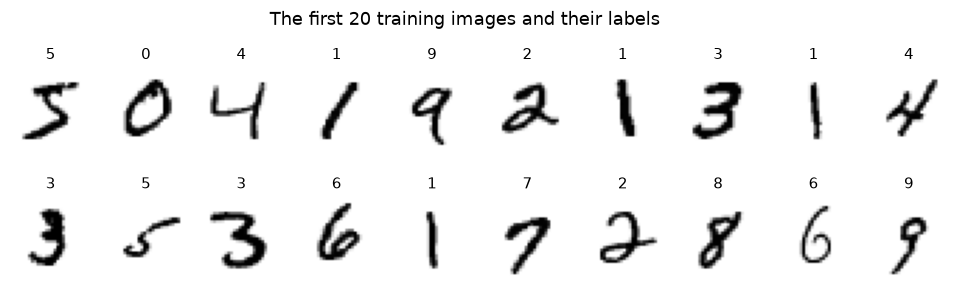

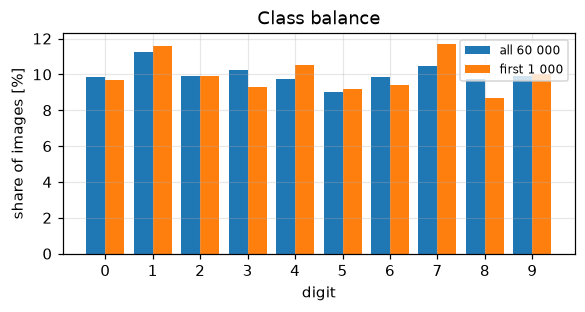

In [4]:
fig, axes = plt.subplots(2, 10, figsize=(11, 2.8))
for i, ax in enumerate(axes.flat):
    ax.imshow(train_images_raw[i], cmap="gray_r")     # gray_r: dark ink on white paper
    ax.set_title(f"{train_labels_raw[i]}", fontsize=10)
    ax.axis("off")
fig.suptitle("The first 20 training images and their labels", y=1.02)
plt.show()

fig, ax = plt.subplots(figsize=(6, 2.6))
counts_train = np.bincount(train_labels_raw, minlength=NUM_CLASSES)   # images per digit
counts_first = np.bincount(train_labels_raw[:1000], minlength=NUM_CLASSES)
ax.bar(np.arange(10) - 0.2, counts_train / counts_train.sum() * 100, width=0.4, label="all 60 000")
ax.bar(np.arange(10) + 0.2, counts_first / counts_first.sum() * 100, width=0.4, label="first 1 000")
ax.set_xticks(range(10)); ax.set_xlabel("digit"); ax.set_ylabel("share of images [%]")
ax.legend(fontsize=8); ax.set_title("Class balance")
plt.show()

## 5. Building blocks

All pieces are small functions or classes that map one-to-one onto the equations of Section 2:

| Code | Equation / section |
|---|---|
| `relu`, `relu_grad` | 2.3 |
| `softmax`, `mse_loss`, `cross_entropy_loss` | 2.4 – each returns the loss **and** $\delta^{(L)}=\partial\mathcal L/\partial Z^{(L)}$ |
| `MLP.forward` | 2.2 (+ dropout, 2.9) |
| `MLP.backward` | 2.6 – the four boxed equations |
| `SGD`, `Adam` | 2.5, 2.11 |
| `train` | 2.7 / 2.10 – mini-batches, shuffling, evaluation, checkpoint selection |

### 5.1 Activation and loss functions

In [5]:
def relu(z):
    """ReLU(z) = max(0, z), element-wise."""
    return np.maximum(z, 0)


def relu_grad(z):
    """dReLU/dz = 1 for z > 0, else 0 (we use 0 at z = 0). Returned in the dtype of z."""
    return (z > 0).astype(z.dtype)


def softmax(z):
    """Row-wise softmax. Subtracting the row maximum does not change the result but prevents overflow in exp."""
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def mse_loss(out, Y):
    """L = (1/B) * sum_i 0.5*||out_i - y_i||^2   ->  returns (L, dL/d out)."""
    B = len(Y)
    diff = out - Y                               # (B, 10) prediction minus target
    loss = 0.5 * np.sum(diff ** 2) / B
    delta = diff / B                             # dL/d out = (out - Y)/B   (Section 2.4a)
    return loss, delta


def cross_entropy_loss(z, Y, eps=1e-12):
    """Softmax + cross-entropy on raw scores z   ->  returns (L, dL/dz)."""
    B = len(Y)
    P = softmax(z)                               # probabilities (B, 10)
    loss = -np.sum(Y * np.log(P + eps)) / B      # eps protects log(0)
    delta = (P - Y) / B                          # dL/dz = (P - Y)/B         (Section 2.4b)
    return loss, delta


LOSSES = {"mse": mse_loss, "ce": cross_entropy_loss}

### 5.2 The multi-layer perceptron

`MLP(sizes=[784, 100, 10])` creates one weight matrix per pair of consecutive layer sizes, so any depth is possible.
Hidden layers use ReLU (and optionally dropout), the output layer is linear (its scores go to MSE or to softmax-CE).

`forward` returns the output **and** a `cache` with everything `backward` needs: the inputs $A^{(l-1)}$ of every layer,
the pre-activations $Z^{(l)}$ and the dropout masks. `backward` implements the boxed equations of Section 2.6 in a loop
running from the last layer to the first.

Parameters are kept in one flat list `params = [W1, b1, W2, b2, ...]` (without biases: `[W1, W2, ...]`), and
`backward` returns gradients in the **same order**, so an optimiser simply walks the two lists in parallel.

In [6]:
class MLP:
    """Fully-connected ReLU network written with NumPy only.

    sizes     : list of layer widths, e.g. [784, 100, 10]
    bias      : include bias vectors b^(l)
    init      : 'uniform' -> U(-init_scale, init_scale) (Trask);  'he' -> N(0, 2/n_in)
    dropout_p : probability of switching OFF a hidden unit during training (0 = no dropout)
    rng       : numpy Generator used for the initialisation AND the dropout masks
    """

    def __init__(self, sizes, bias=True, init="he", init_scale=0.1, dropout_p=0.0,
                 rng=None, dtype=np.float32):
        self.sizes, self.bias, self.dropout_p, self.dtype = list(sizes), bias, dropout_p, dtype
        self.rng = rng if rng is not None else np.random.default_rng(SEED)
        self.W, self.b = [], []
        for n_in, n_out in zip(sizes[:-1], sizes[1:]):
            if init == "uniform":
                W = self.rng.uniform(-init_scale, init_scale, size=(n_in, n_out))
            elif init == "he":
                W = self.rng.normal(0.0, np.sqrt(2.0 / n_in), size=(n_in, n_out))
            else:
                raise ValueError(f"unknown init '{init}'")
            self.W.append(W.astype(dtype))
            self.b.append(np.zeros(n_out, dtype=dtype))   # biases start at zero (unused if bias=False)

    # --- parameter bookkeeping -------------------------------------------------------------------
    @property
    def params(self):
        """Flat list of the trainable arrays in a fixed order: [W1, b1, W2, b2, ...] or [W1, W2, ...]."""
        if self.bias:
            return [p for Wb in zip(self.W, self.b) for p in Wb]
        return list(self.W)

    def n_params(self):
        return sum(p.size for p in self.params)

    def get_state(self):
        """Deep copy of all parameters (used for checkpoints)."""
        return [p.copy() for p in self.params]

    def set_state(self, state):
        """Copy a saved state back IN PLACE (so optimisers keep pointing at the same arrays)."""
        for p, s in zip(self.params, state):
            p[...] = s

    # --- forward pass ---------------------------------------------------------------------------
    def forward(self, X, train=False, masks=None):
        """Return (output scores, cache).

        train=True switches dropout on. 'masks' can be given to reuse fixed dropout masks
        (needed by the gradient check, where the same network must be evaluated many times).
        """
        A = X
        cache = {"A": [], "Z": [], "masks": []}
        L = len(self.W)
        for l in range(L):
            cache["A"].append(A)                       # input of layer l, needed for dL/dW
            Z = A @ self.W[l]                          # (B, n_in) @ (n_in, n_out) -> (B, n_out)
            if self.bias:
                Z = Z + self.b[l]                      # broadcast the bias over the batch rows
            if l == L - 1:                             # output layer: linear scores, no activation
                return Z, cache
            cache["Z"].append(Z)                       # pre-activation, needed for ReLU'(Z)
            A = relu(Z)
            if train and self.dropout_p > 0.0:
                if masks is None:
                    keep = self.rng.random(A.shape) >= self.dropout_p      # Bernoulli(1-p) keep-mask
                    m = keep.astype(self.dtype) / (1.0 - self.dropout_p)  # inverted dropout scaling
                else:
                    m = masks[l]
                A = A * m
                cache["masks"].append(m)
            else:
                cache["masks"].append(None)

    # --- backward pass --------------------------------------------------------------------------
    def backward(self, delta, cache):
        """Back-propagate delta = dL/dZ^(L) and return the gradients in the order of self.params."""
        L = len(self.W)
        gW, gb = [None] * L, [None] * L
        for l in reversed(range(L)):
            A_prev = cache["A"][l]
            gW[l] = A_prev.T @ delta                   # dL/dW^(l) = A^(l-1)^T delta^(l)
            gb[l] = delta.sum(axis=0)                  # dL/db^(l) = sum over the batch
            if l > 0:
                delta = delta @ self.W[l].T            # dL/dA^(l-1)
                if cache["masks"][l - 1] is not None:
                    delta = delta * cache["masks"][l - 1]      # through dropout: same mask (incl. 1/(1-p))
                delta = delta * relu_grad(cache["Z"][l - 1])   # through ReLU
        if self.bias:
            return [g for gWb in zip(gW, gb) for g in gWb]
        return gW

    # --- convenience ----------------------------------------------------------------------------
    def predict(self, X):
        """Predicted digit for every row of X (dropout off)."""
        return self.forward(X, train=False)[0].argmax(axis=1)


demo = MLP([INPUT_SIZE, 100, NUM_CLASSES], bias=False, init="uniform")
print(f"MLP {demo.sizes}, bias={demo.bias}: {demo.n_params():,} trainable parameters")
print("parameter shapes:", [p.shape for p in demo.params])

MLP [784, 100, 10], bias=False: 79,400 trainable parameters
parameter shapes: [(784, 100), (100, 10)]


### 5.3 Optimisers

Both optimisers update the parameter arrays **in place** (`p -= ...`). Because `MLP.params` returns references to the
model's own arrays, the model sees the new values immediately.

In [7]:
class SGD:
    """theta <- theta - lr * v,   v <- momentum * v + grad   (momentum = 0 gives plain SGD)."""

    def __init__(self, params, lr, momentum=0.0):
        self.params, self.lr, self.momentum = params, lr, momentum
        self.v = [np.zeros_like(p) for p in params]          # velocities (only used if momentum > 0)

    def step(self, grads):
        for p, g, v in zip(self.params, grads, self.v):
            if self.momentum > 0.0:
                v *= self.momentum
                v += g
                g = v
            p -= self.lr * g                                  # in-place update


class Adam:
    """Adam (Kingma & Ba, 2015) with bias correction, Section 2.11."""

    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        self.params, self.lr, self.eps = params, lr, eps
        self.b1, self.b2 = betas
        self.m = [np.zeros_like(p) for p in params]          # 1st moment (mean of g)
        self.v = [np.zeros_like(p) for p in params]          # 2nd moment (mean of g^2)
        self.t = 0                                            # step counter for bias correction

    def step(self, grads):
        self.t += 1
        c1 = 1.0 - self.b1 ** self.t                          # bias corrections: early averages are
        c2 = 1.0 - self.b2 ** self.t                          # biased towards 0 because m, v start at 0
        for p, g, m, v in zip(self.params, grads, self.m, self.v):
            m *= self.b1; m += (1.0 - self.b1) * g
            v *= self.b2; v += (1.0 - self.b2) * g * g
            p -= self.lr * (m / c1) / (np.sqrt(v / c2) + self.eps)

### 5.4 Evaluation and the training loop

`train` is used by **all** experiments. One epoch:

1. draw a fresh random permutation of the training indices (shuffling);
2. for every mini-batch: forward (dropout on) → loss and $\delta^{(L)}$ → backward → optimiser step;
3. evaluate on the validation and/or test data with dropout **off**, every `eval_every` epochs;
4. if a validation set is given, keep a copy of the parameters with the lowest validation loss (checkpoint selection).

The *training* loss and accuracy are accumulated from the mini-batches during the epoch, i.e. with dropout on and with
weights that change during the epoch – exactly as Trask reports them. They are therefore slightly pessimistic compared
with a clean evaluation after the epoch.

`batch_size=1` gives stochastic gradient descent, `batch_size=len(X)` full-batch gradient descent.

In [8]:
def evaluate(model, X, Y, loss="mse", chunk=10_000):
    """Loss and accuracy of the model on (X, Y) with dropout OFF. Processed in chunks to limit memory."""
    loss_fn = LOSSES[loss]
    total_loss, correct = 0.0, 0
    for s in range(0, len(X), chunk):
        out, _ = model.forward(X[s:s + chunk], train=False)
        l, _ = loss_fn(out, Y[s:s + chunk])
        total_loss += l * len(out)                                   # undo the 1/B of the mean
        correct += int((out.argmax(1) == Y[s:s + chunk].argmax(1)).sum())
    return total_loss / len(X), correct / len(X)


def train(model, opt, X, Y, epochs, batch_size, loss="mse",
          X_val=None, Y_val=None, X_test=None, Y_test=None,
          eval_every=1, shuffle_rng=None, desc="training", print_every=None):
    """Generic mini-batch training loop. Returns (history, best) where best holds the checkpoint
    with the lowest validation loss (or the final state if no validation set is given)."""
    loss_fn = LOSSES[loss]
    shuffle_rng = shuffle_rng if shuffle_rng is not None else np.random.default_rng(SEED + 100_000)
    N = len(X)
    hist = {k: [] for k in ("epoch", "train_loss", "train_acc", "val_loss", "val_acc", "test_loss", "test_acc")}
    best = {"epoch": 0, "val_loss": np.inf, "state": None}

    pbar = tqdm(range(1, epochs + 1), desc=desc, leave=False)
    for epoch in pbar:
        perm = shuffle_rng.permutation(N)                            # 1. shuffle
        run_loss, run_correct = 0.0, 0
        for s in range(0, N, batch_size):                            # 2. mini-batches
            idx = perm[s:s + batch_size]
            xb, yb = X[idx], Y[idx]
            out, cache = model.forward(xb, train=True)               #    forward (dropout ON)
            l, delta = loss_fn(out, yb)                              #    loss and dL/dZ^(L)
            grads = model.backward(delta, cache)                     #    back-propagation
            opt.step(grads)                                          #    parameter update
            run_loss += l * len(idx)
            run_correct += int((out.argmax(1) == yb.argmax(1)).sum())

        if epoch % eval_every == 0 or epoch == epochs or epoch == 1:  # 3. evaluation (dropout OFF)
            hist["epoch"].append(epoch)
            hist["train_loss"].append(run_loss / N)
            hist["train_acc"].append(run_correct / N)
            for name, Xe, Ye in (("val", X_val, Y_val), ("test", X_test, Y_test)):
                if Xe is not None:
                    le, ae = evaluate(model, Xe, Ye, loss)
                    hist[f"{name}_loss"].append(le); hist[f"{name}_acc"].append(ae)
            if X_val is not None and hist["val_loss"][-1] < best["val_loss"]:   # 4. checkpoint
                best = {"epoch": epoch, "val_loss": hist["val_loss"][-1], "state": model.get_state()}
            post = {"train_acc": f"{hist['train_acc'][-1]:.3f}"}
            if X_val is not None:  post["val_acc"] = f"{hist['val_acc'][-1]:.3f}"
            if X_test is not None: post["test_acc"] = f"{hist['test_acc'][-1]:.3f}"
            pbar.set_postfix(post)
            if print_every and (epoch % print_every == 0 or epoch == 1 or epoch == epochs):
                tqdm.write(f"epoch {epoch:4d} | " + "  ".join(f"{k} {v}" for k, v in post.items())
                           + f"  train_loss {hist['train_loss'][-1]:.4f}")
    if best["state"] is None:                                        # no validation set: final state
        best = {"epoch": epochs, "val_loss": np.nan, "state": model.get_state()}
    return hist, best

## 6. Gradient check: is the back-propagation correct?

A hand-written backward pass is easy to get subtly wrong (a missing transpose, a forgotten mask) and the network may
still learn *something*, which hides the bug. The **finite-difference check** compares each analytic gradient with

$$\frac{\partial\mathcal L}{\partial\theta_j} \approx \frac{\mathcal L(\theta_j+\varepsilon) - \mathcal L(\theta_j-\varepsilon)}{2\varepsilon},
\qquad \text{relative error} = \frac{|g_\text{num}-g_\text{bp}|}{\max(|g_\text{num}|+|g_\text{bp}|,\,10^{-12})}.$$

The central difference has an error of order $\varepsilon^2$. In double precision with $\varepsilon=10^{-5}$ correct
gradients give relative errors around $10^{-7}$ or smaller; errors above $10^{-3}$ indicate a bug. We check a small
network with biases, both losses, and dropout (with the masks frozen so that every evaluation uses the same
sub-network). (ReLU has a kink at 0; if a perturbation crosses it the check of that entry can fail although the code
is correct – with random data this is rare.)

In [9]:
def gradient_check(loss="mse", dropout_p=0.0, n_checks=25, eps=1e-5, seed=0):
    """Compare back-propagation with central finite differences on a small float64 network."""
    rng = np.random.default_rng(seed)
    net = MLP([INPUT_SIZE, 16, 12, NUM_CLASSES], bias=True, init="he", dropout_p=dropout_p,
              rng=np.random.default_rng(seed), dtype=np.float64)
    for b in net.b:                                         # non-zero biases so their gradient is tested too
        b[...] = rng.normal(0, 0.1, b.shape)
    X, Y = X_train_full[:8].astype(np.float64), Y_train_full[:8].astype(np.float64)

    out, cache = net.forward(X, train=True)                 # draws (and stores) the dropout masks once
    masks = cache["masks"]
    _, delta = LOSSES[loss](out, Y)
    grads = net.backward(delta, cache)

    def L_of_params():                                      # loss with the SAME masks every time
        return LOSSES[loss](net.forward(X, train=True, masks=masks)[0], Y)[0]

    worst = 0.0
    for p, g in zip(net.params, grads):
        for _ in range(n_checks):
            j = tuple(rng.integers(0, s) for s in p.shape)  # random entry of this parameter array
            old = p[j]
            p[j] = old + eps; Lp = L_of_params()
            p[j] = old - eps; Lm = L_of_params()
            p[j] = old                                      # restore
            g_num = (Lp - Lm) / (2 * eps)
            rel = abs(g_num - g[j]) / max(abs(g_num) + abs(g[j]), 1e-12)
            worst = max(worst, rel)
    return worst


for loss in ("mse", "ce"):
    for p in (0.0, 0.5):
        err = gradient_check(loss=loss, dropout_p=p)
        status = "OK" if err < 1e-5 else "CHECK!"
        print(f"loss={loss:3s}  dropout_p={p:.1f}  ->  max relative error {err:.2e}   {status}")

loss=mse  dropout_p=0.0  ->  max relative error 5.05e-09   OK
loss=mse  dropout_p=0.5  ->  max relative error 1.57e-07   OK
loss=ce   dropout_p=0.0  ->  max relative error 1.05e-08   OK
loss=ce   dropout_p=0.5  ->  max relative error 8.14e-07   OK


## 7. Experiment A – stochastic gradient descent (one image per step)

This reproduces `chapter_8_1` (Trask, ch. 8): the first **1000** training images, network $784\to100\to10$ without biases,
uniform initialisation in $[-0.1, 0.1]$, MSE loss, learning rate $\eta=0.005$ and **one weight update per image**.
Run 1 has no dropout, run 2 uses dropout with $p=0.5$.

Differences to the original code: the images are shuffled every epoch, the dropout derivative includes the factor 2
(Section 2.9), and the test set is evaluated vectorised (all 10 000 images in one matrix product) every 10 epochs. The
test accuracy is only *monitored* here, no decision is based on it.

**What to look for.** Without dropout the training accuracy reaches 100 % within a few dozen epochs (memorisation)
while the test accuracy peaks early and then slowly *decreases*: overfitting. With dropout the training accuracy stays
below 100 % and the gap between training and test accuracy is smaller. Whether dropout also gives a higher *best* test
accuracy is not guaranteed in this small set-up – a single run cannot decide it; Experiment C examines it properly.

In [10]:
# ---- hyper-parameters of Experiment A (as in chapter_8_1) ---------------------------------------
A_N_TRAIN   = 1000      # first 1000 training images
A_HIDDEN    = 100       # hidden neurons
A_LR        = 0.005     # learning rate eta (Trask: alpha)
A_EPOCHS    = 300       # passes through the 1000 images
A_EVAL      = 10        # evaluate the test set every 10 epochs

X_a, Y_a = X_train_full[:A_N_TRAIN], Y_train_full[:A_N_TRAIN]

results_A = {}
for p in (0.0, 0.5):
    model = MLP([INPUT_SIZE, A_HIDDEN, NUM_CLASSES], bias=False, init="uniform", init_scale=0.1,
                dropout_p=p, rng=np.random.default_rng(SEED))            # same initial weights for both runs
    opt = SGD(model.params, lr=A_LR)
    t0 = time.time()
    hist, _ = train(model, opt, X_a, Y_a, epochs=A_EPOCHS, batch_size=1, loss="mse",
                    X_test=X_test, Y_test=Y_test, eval_every=A_EVAL,
                    shuffle_rng=np.random.default_rng(SEED + 100_000),
                    desc=f"A: SGD, dropout p={p}", print_every=50)
    results_A[p] = {"hist": hist, "time": time.time() - t0, "model": model}
    best_i = int(np.argmax(hist["test_acc"]))
    print(f"--> dropout p={p}: {results_A[p]['time']:.1f} s, final train acc {hist['train_acc'][-1]:.4f}, "
          f"final test acc {hist['test_acc'][-1]:.4f} (highest monitored: {hist['test_acc'][best_i]:.4f} "
          f"at epoch {hist['epoch'][best_i]})\n")

A: SGD, dropout p=0.0:   0%|          | 0/300 [00:00<?, ?it/s]

epoch    1 | train_acc 0.581  test_acc 0.714  train_loss 0.3444
epoch   50 | train_acc 1.000  test_acc 0.888  train_loss 0.0179
epoch  100 | train_acc 1.000  test_acc 0.884  train_loss 0.0065
epoch  150 | train_acc 1.000  test_acc 0.878  train_loss 0.0034
epoch  200 | train_acc 1.000  test_acc 0.875  train_loss 0.0021
epoch  250 | train_acc 1.000  test_acc 0.872  train_loss 0.0014
epoch  300 | train_acc 1.000  test_acc 0.871  train_loss 0.0010
--> dropout p=0.0: 34.2 s, final train acc 1.0000, final test acc 0.8710 (highest monitored: 0.8919 at epoch 30)



A: SGD, dropout p=0.5:   0%|          | 0/300 [00:00<?, ?it/s]

epoch    1 | train_acc 0.392  test_acc 0.655  train_loss 0.4294
epoch   50 | train_acc 0.954  test_acc 0.880  train_loss 0.1051
epoch  100 | train_acc 0.970  test_acc 0.877  train_loss 0.0888
epoch  150 | train_acc 0.975  test_acc 0.878  train_loss 0.0814
epoch  200 | train_acc 0.973  test_acc 0.873  train_loss 0.0803
epoch  250 | train_acc 0.981  test_acc 0.873  train_loss 0.0818
epoch  300 | train_acc 0.982  test_acc 0.868  train_loss 0.0689
--> dropout p=0.5: 35.7 s, final train acc 0.9820, final test acc 0.8681 (highest monitored: 0.8818 at epoch 80)



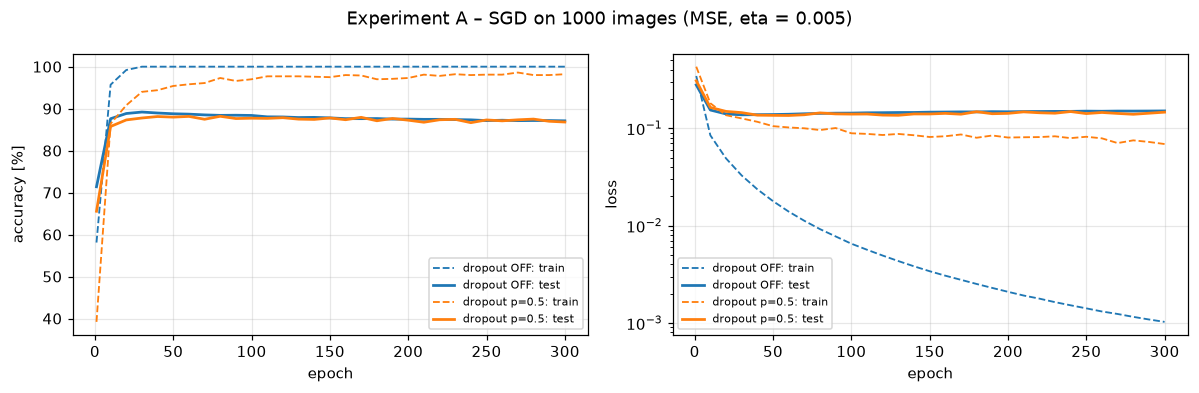

In [11]:
def plot_curves(results, title, labels):
    """Accuracy (train dashed / test or val solid) and loss curves for a dict of runs."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
    for (key, res), lab, col in zip(results.items(), labels, ("C0", "C1", "C2", "C3")):
        h = res["hist"]
        ev = "val" if h["val_acc"] else "test"
        a1.plot(h["epoch"], np.array(h["train_acc"]) * 100, "--", color=col, lw=1.2, label=f"{lab}: train")
        a1.plot(h["epoch"], np.array(h[f"{ev}_acc"]) * 100, "-", color=col, lw=1.8, label=f"{lab}: {ev}")
        a2.plot(h["epoch"], h["train_loss"], "--", color=col, lw=1.2, label=f"{lab}: train")
        a2.plot(h["epoch"], h[f"{ev}_loss"], "-", color=col, lw=1.8, label=f"{lab}: {ev}")
    a1.set_xlabel("epoch"); a1.set_ylabel("accuracy [%]"); a1.legend(fontsize=7)
    a2.set_xlabel("epoch"); a2.set_ylabel("loss"); a2.set_yscale("log"); a2.legend(fontsize=7)
    fig.suptitle(title); plt.tight_layout(); plt.show()


plot_curves(results_A, "Experiment A – SGD on 1000 images (MSE, eta = 0.005)",
            ["dropout OFF", "dropout p=0.5"])

## 8. Experiment B – mini-batch gradient descent

This reproduces the **correct, vectorised** version of `chapter_8_2_batch`: the same 1000 images and network, dropout
$p=0.5$, but $B=100$ images per update. With our mean loss the learning rate equivalent to Trask's `alpha = 0.001`
(summed loss) is $\eta = B\cdot0.001 = 0.1$ (Section 2.7).

Per epoch there are now only 10 updates instead of 1000, but each update uses a much better gradient estimate and is
computed as **one** matrix product of shape $(100,784)\times(784,100)$ – far more efficient than 100 products with single
rows. Compare the wall-clock times of Experiments A and B.

B: mini-batch, dropout p=0.0:   0%|          | 0/300 [00:00<?, ?it/s]

epoch    1 | train_acc 0.252  test_acc 0.449  train_loss 0.4774
epoch   50 | train_acc 0.971  test_acc 0.875  train_loss 0.0769
epoch  100 | train_acc 0.997  test_acc 0.888  train_loss 0.0444
epoch  150 | train_acc 1.000  test_acc 0.890  train_loss 0.0299
epoch  200 | train_acc 1.000  test_acc 0.887  train_loss 0.0216
epoch  250 | train_acc 1.000  test_acc 0.884  train_loss 0.0164
epoch  300 | train_acc 1.000  test_acc 0.884  train_loss 0.0128
--> dropout p=0.0: 0.7 s, final train acc 1.0000, final test acc 0.8837 (highest monitored: 0.8901 at epoch 150)



B: mini-batch, dropout p=0.5:   0%|          | 0/300 [00:00<?, ?it/s]

epoch    1 | train_acc 0.172  test_acc 0.412  train_loss 0.5726
epoch   50 | train_acc 0.883  test_acc 0.860  train_loss 0.1596
epoch  100 | train_acc 0.926  test_acc 0.877  train_loss 0.1240
epoch  150 | train_acc 0.942  test_acc 0.880  train_loss 0.1095
epoch  200 | train_acc 0.956  test_acc 0.880  train_loss 0.1052
epoch  250 | train_acc 0.958  test_acc 0.878  train_loss 0.1039
epoch  300 | train_acc 0.971  test_acc 0.874  train_loss 0.0893
--> dropout p=0.5: 0.8 s, final train acc 0.9710, final test acc 0.8741 (highest monitored: 0.8816 at epoch 170)



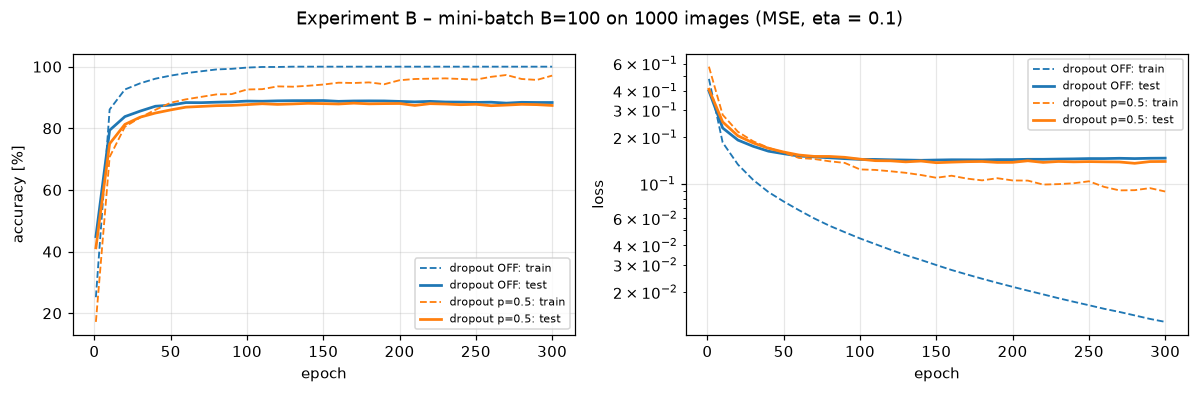

Wall-clock time per run:
  dropout p=0.0:  A (B=1)   34.2 s   |   B (B=100)    0.7 s
  dropout p=0.5:  A (B=1)   35.7 s   |   B (B=100)    0.8 s


In [12]:
B_BATCH  = 100
B_LR     = 0.1           # = 100 * 0.001 (Trask's summed-loss alpha), see Section 2.7
B_EPOCHS = 300

results_B = {}
for p in (0.0, 0.5):
    model = MLP([INPUT_SIZE, A_HIDDEN, NUM_CLASSES], bias=False, init="uniform", init_scale=0.1,
                dropout_p=p, rng=np.random.default_rng(SEED))
    opt = SGD(model.params, lr=B_LR)
    t0 = time.time()
    hist, _ = train(model, opt, X_a, Y_a, epochs=B_EPOCHS, batch_size=B_BATCH, loss="mse",
                    X_test=X_test, Y_test=Y_test, eval_every=A_EVAL,
                    shuffle_rng=np.random.default_rng(SEED + 100_000),
                    desc=f"B: mini-batch, dropout p={p}", print_every=50)
    results_B[p] = {"hist": hist, "time": time.time() - t0}
    best_i = int(np.argmax(hist["test_acc"]))
    print(f"--> dropout p={p}: {results_B[p]['time']:.1f} s, final train acc {hist['train_acc'][-1]:.4f}, "
          f"final test acc {hist['test_acc'][-1]:.4f} (highest monitored: {hist['test_acc'][best_i]:.4f} "
          f"at epoch {hist['epoch'][best_i]})\n")

plot_curves(results_B, f"Experiment B – mini-batch B={B_BATCH} on 1000 images (MSE, eta = {B_LR})",
            ["dropout OFF", "dropout p=0.5"])

print("Wall-clock time per run:")
for p in (0.0, 0.5):
    print(f"  dropout p={p}:  A (B=1) {results_A[p]['time']:6.1f} s   |   B (B={B_BATCH}) {results_B[p]['time']:6.1f} s")

## 9. Experiment C – dropout ON vs OFF over 5 seeds with checkpoint selection

A single run cannot tell whether dropout helps: the outcome depends on the random initialisation, the shuffling and
the dropout masks. This experiment (from `chapter_8_3_..._master`) therefore uses

| Factor | Setting |
|---|---|
| data | first 1000 training images split into **800 training + 200 validation**; 10 000 test images |
| model | $784\to100\to10$, no biases, uniform init, MSE, mini-batch $B=100$, $\eta=0.1$, 300 epochs |
| conditions | dropout $p=0.5$ (ON) and $p=0$ (OFF) |
| seeds | 1, 2, 3, 4, 5 |
| pairing | for each seed, ON and OFF start from **identical weights** and see the **same batch order** |
| checkpoint | epoch with the lowest **validation** loss, chosen separately for every run |
| test | evaluated **once** per run, with that run's checkpoint |

Two separate random generators are used per run: one for the initialisation and the dropout masks
(`seed`), one for the shuffling (`seed + 100000`). The dropout masks consume random numbers, so with a single generator
the ON run would see a different batch order than the OFF run and the comparison would no longer be paired.

In [13]:
C_SEEDS  = [1, 2, 3, 4, 5]
C_N_VAL  = 200
C_EPOCHS = 300

X_c_tr, Y_c_tr   = X_train_full[:A_N_TRAIN - C_N_VAL], Y_train_full[:A_N_TRAIN - C_N_VAL]       # 800 images
X_c_val, Y_c_val = X_train_full[A_N_TRAIN - C_N_VAL:A_N_TRAIN], Y_train_full[A_N_TRAIN - C_N_VAL:A_N_TRAIN]  # 200

results_C = {}
t0 = time.time()
for seed in C_SEEDS:
    for p, tag in ((0.5, "on"), (0.0, "off")):
        model = MLP([INPUT_SIZE, A_HIDDEN, NUM_CLASSES], bias=False, init="uniform", init_scale=0.1,
                    dropout_p=p, rng=np.random.default_rng(seed))              # init + dropout masks
        opt = SGD(model.params, lr=B_LR)
        hist, best = train(model, opt, X_c_tr, Y_c_tr, epochs=C_EPOCHS, batch_size=B_BATCH, loss="mse",
                           X_val=X_c_val, Y_val=Y_c_val, eval_every=1,
                           shuffle_rng=np.random.default_rng(seed + 100_000),  # batch order only
                           desc=f"C: seed {seed}, dropout {tag}")
        model.set_state(best["state"])                                         # restore the checkpoint
        test_loss, test_acc = evaluate(model, X_test, Y_test, "mse")           # the ONE test evaluation
        results_C[(seed, tag)] = {"hist": hist, "best_epoch": best["epoch"],
                                  "test_acc": test_acc, "test_loss": test_loss}
        print(f"seed {seed}  dropout {tag:3s}: best val epoch {best['epoch']:3d}, test acc {test_acc * 100:.2f} %")
print(f"\nExperiment C finished in {time.time() - t0:.1f} s")

C: seed 1, dropout on:   0%|          | 0/300 [00:00<?, ?it/s]

seed 1  dropout on : best val epoch 290, test acc 86.85 %


C: seed 1, dropout off:   0%|          | 0/300 [00:00<?, ?it/s]

seed 1  dropout off: best val epoch 146, test acc 88.45 %


C: seed 2, dropout on:   0%|          | 0/300 [00:00<?, ?it/s]

seed 2  dropout on : best val epoch 172, test acc 88.11 %


... (10 outputs left out)

C: seed 5, dropout on:   0%|          | 0/300 [00:00<?, ?it/s]

seed 5  dropout on : best val epoch 267, test acc 87.07 %


C: seed 5, dropout off:   0%|          | 0/300 [00:00<?, ?it/s]

seed 5  dropout off: best val epoch 119, test acc 87.11 %

Experiment C finished in 5.7 s


In [14]:
acc_on  = np.array([results_C[(s, "on")]["test_acc"] for s in C_SEEDS]) * 100
acc_off = np.array([results_C[(s, "off")]["test_acc"] for s in C_SEEDS]) * 100
diff    = acc_on - acc_off                                   # paired differences (same seed)

print(f"{'seed':>4} | {'dropout ON':>10} | {'dropout OFF':>11} | {'ON - OFF':>8}")
print("-" * 44)
for s, a, b, d in zip(C_SEEDS, acc_on, acc_off, diff):
    print(f"{s:>4} | {a:>9.2f}% | {b:>10.2f}% | {d:>+7.2f}%")
print("-" * 44)
# ddof=1: sample standard deviation (unbiased variance estimate from 5 values)
print(f"mean | {acc_on.mean():>9.2f}% | {acc_off.mean():>10.2f}% | {diff.mean():>+7.2f}%")
print(f" std | {acc_on.std(ddof=1):>9.2f}% | {acc_off.std(ddof=1):>10.2f}% | {diff.std(ddof=1):>7.2f}%")

if diff.mean() > diff.std(ddof=1):
    verdict = "dropout ON gives consistently higher test accuracy on these seeds"
elif diff.mean() < -diff.std(ddof=1):
    verdict = "dropout OFF gives consistently higher test accuracy on these seeds"
else:
    verdict = "no consistent difference (|mean| < 1 std) - more seeds or more data needed"
print(f"\nVerdict: {verdict}.")
print("(5 seeds measure the sensitivity to training randomness on ONE fixed data split.)")

seed | dropout ON | dropout OFF | ON - OFF
--------------------------------------------
   1 |     86.85% |      88.45% |   -1.60%
   2 |     88.11% |      88.07% |   +0.04%
   3 |     87.35% |      87.74% |   -0.39%
   4 |     87.34% |      87.24% |   +0.10%
   5 |     87.07% |      87.11% |   -0.04%
--------------------------------------------
mean |     87.34% |      87.72% |   -0.38%
 std |      0.48% |       0.56% |    0.71%

Verdict: no consistent difference (|mean| < 1 std) - more seeds or more data needed.
(5 seeds measure the sensitivity to training randomness on ONE fixed data split.)


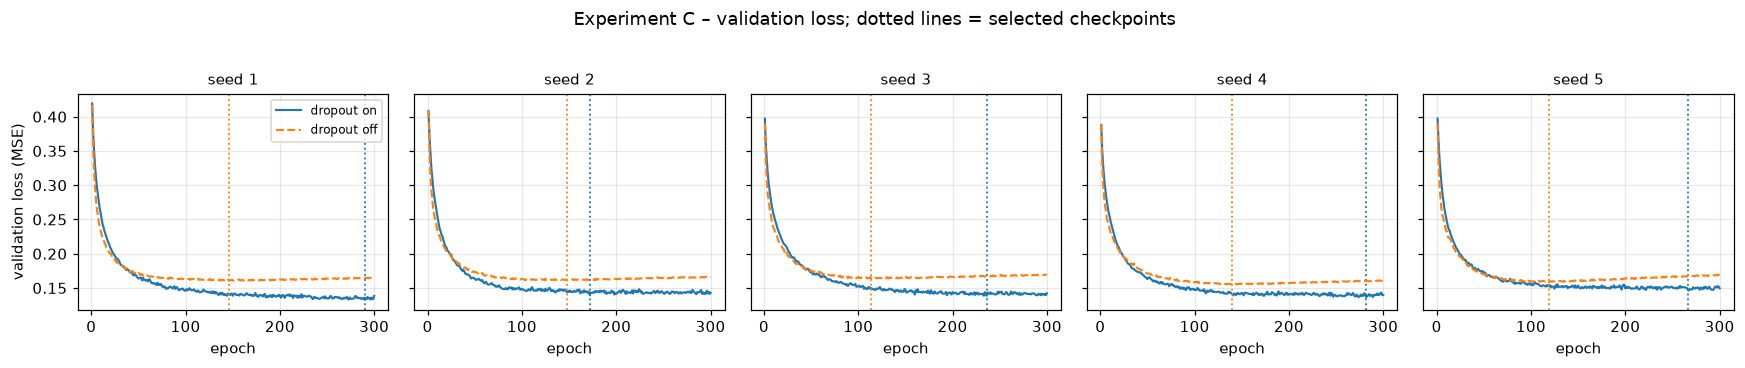

In [15]:
fig, axes = plt.subplots(1, len(C_SEEDS), figsize=(3.2 * len(C_SEEDS), 3.2), sharey=True)
for ax, s in zip(axes, C_SEEDS):
    for tag, col, ls in (("on", "C0", "-"), ("off", "C1", "--")):
        r = results_C[(s, tag)]
        ax.plot(r["hist"]["epoch"], r["hist"]["val_loss"], ls, color=col, lw=1.4, label=f"dropout {tag}")
        ax.axvline(r["best_epoch"], color=col, ls=":", lw=1.2)          # selected checkpoint
    ax.set_title(f"seed {s}", fontsize=10); ax.set_xlabel("epoch")
axes[0].set_ylabel("validation loss (MSE)"); axes[0].legend(fontsize=8)
fig.suptitle("Experiment C – validation loss; dotted lines = selected checkpoints", y=1.03)
plt.tight_layout(); plt.show()

## 10. Experiment D – a modern MLP on the full training set

The previous experiments deliberately used a tiny data set to show overfitting. Now we use the standard ingredients:

| Choice | Experiments A–C | Experiment D | Reason |
|---|---|---|---|
| training data | 800–1000 images | 54 000 (+ 6 000 validation) | more data is the best regulariser |
| architecture | $784\to100\to10$ | $784\to256\to128\to10$ | more capacity, two hidden layers |
| biases | no | yes | lets every unit shift its threshold |
| initialisation | $\mathcal U(-0.1,0.1)$ | He | variance-preserving for ReLU (2.8) |
| loss | MSE | softmax + cross-entropy | standard for classification (2.4b) |
| optimiser | SGD | Adam, $\eta=10^{-3}$ | per-parameter step sizes (2.11) |
| dropout | 0 / 0.5 | 0.2 | mild regularisation for a large data set |
| batch size | 1 / 100 | 128 | |

The validation set (the last 6 000 training images) selects the best epoch; the test set is used once at the end.

MLP [784, 256, 128, 10]: 235,146 trainable parameters


D: full MNIST:   0%|          | 0/15 [00:00<?, ?it/s]

epoch    1 | train_acc 0.889  val_acc 0.968  train_loss 0.3722
epoch    2 | train_acc 0.955  val_acc 0.975  train_loss 0.1516
epoch    3 | train_acc 0.967  val_acc 0.976  train_loss 0.1106
epoch    4 | train_acc 0.973  val_acc 0.980  train_loss 0.0873
epoch    5 | train_acc 0.977  val_acc 0.980  train_loss 0.0739
epoch    6 | train_acc 0.980  val_acc 0.980  train_loss 0.0630
epoch    7 | train_acc 0.983  val_acc 0.982  train_loss 0.0538
epoch    8 | train_acc 0.984  val_acc 0.981  train_loss 0.0482
epoch    9 | train_acc 0.986  val_acc 0.981  train_loss 0.0429
epoch   10 | train_acc 0.988  val_acc 0.984  train_loss 0.0380
epoch   11 | train_acc 0.989  val_acc 0.982  train_loss 0.0338
epoch   12 | train_acc 0.989  val_acc 0.984  train_loss 0.0323
epoch   13 | train_acc 0.989  val_acc 0.982  train_loss 0.0310
epoch   14 | train_acc 0.990  val_acc 0.984  train_loss 0.0284
epoch   15 | train_acc 0.991  val_acc 0.984  train_loss 0.0271

training time 6.2 s; best validation epoch 10 (val los

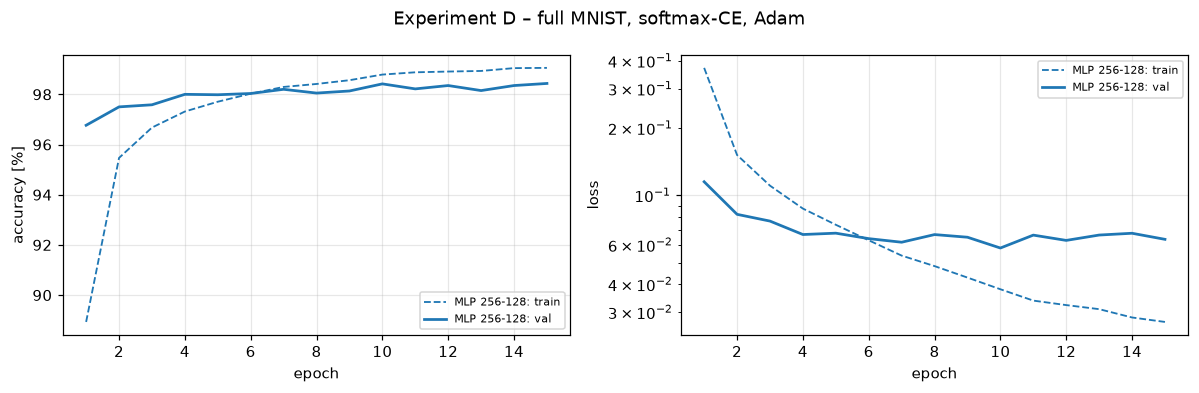

In [16]:
D_N_VAL   = 6000
D_SIZES   = [INPUT_SIZE, 256, 128, NUM_CLASSES]
D_DROPOUT = 0.2
D_LR      = 1e-3
D_BATCH   = 128
D_EPOCHS  = 15

X_d_tr, Y_d_tr   = X_train_full[:-D_N_VAL], Y_train_full[:-D_N_VAL]      # 54 000 images
X_d_val, Y_d_val = X_train_full[-D_N_VAL:], Y_train_full[-D_N_VAL:]      #  6 000 images

model_D = MLP(D_SIZES, bias=True, init="he", dropout_p=D_DROPOUT, rng=np.random.default_rng(SEED))
opt_D = Adam(model_D.params, lr=D_LR)
print(f"MLP {D_SIZES}: {model_D.n_params():,} trainable parameters")

t0 = time.time()
hist_D, best_D = train(model_D, opt_D, X_d_tr, Y_d_tr, epochs=D_EPOCHS, batch_size=D_BATCH, loss="ce",
                       X_val=X_d_val, Y_val=Y_d_val, eval_every=1,
                       shuffle_rng=np.random.default_rng(SEED + 100_000), desc="D: full MNIST", print_every=1)
time_D = time.time() - t0

model_D.set_state(best_D["state"])                                     # restore the best checkpoint
test_loss_D, test_acc_D = evaluate(model_D, X_test, Y_test, "ce")      # ONE final test evaluation
print(f"\ntraining time {time_D:.1f} s; best validation epoch {best_D['epoch']} "
      f"(val loss {best_D['val_loss']:.4f})")
print(f"TEST: loss {test_loss_D:.4f}, accuracy {test_acc_D * 100:.2f} % "
      f"({round(test_acc_D * len(X_test))} / {len(X_test)})")

plot_curves({"D": {"hist": hist_D}}, "Experiment D – full MNIST, softmax-CE, Adam", ["MLP 256-128"])

## 11. Analysis of the final model

### 11.1 Confusion matrix and per-class accuracy

Entry $(j,k)$ counts the test images of true digit $j$ that were predicted as $k$; a perfect classifier has non-zero
entries only on the diagonal. `np.add.at` adds 1 to cell `(true, pred)` for every image, also when the same cell
appears many times.

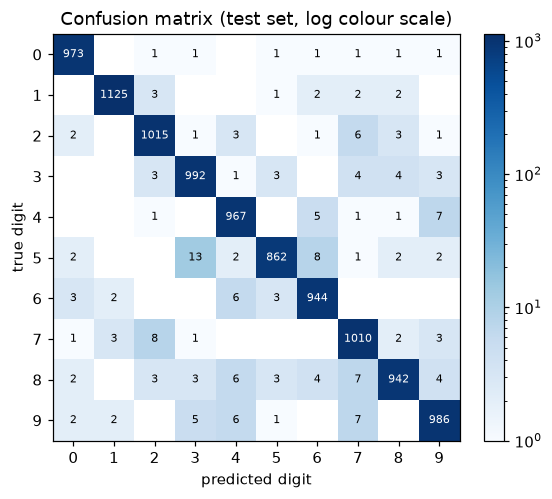

per-class accuracy [%]: 0: 99.3  1: 99.1  2: 98.4  3: 98.2  4: 98.5  5: 96.6  6: 98.5  7: 98.2  8: 96.7  9: 97.7
most frequent confusion: true 5 predicted as 3 (13 times)


In [17]:
pred_D = model_D.predict(X_test)
true_D = test_labels_raw.astype(int)

conf = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)
np.add.at(conf, (true_D, pred_D), 1)                          # unbuffered += 1 at every (true, pred) pair

fig, ax = plt.subplots(figsize=(5.6, 4.8))
im = ax.imshow(conf, cmap="Blues", norm=plt.matplotlib.colors.LogNorm(vmin=1, vmax=conf.max()))
for j in range(NUM_CLASSES):
    for k in range(NUM_CLASSES):
        if conf[j, k]:
            ax.text(k, j, conf[j, k], ha="center", va="center", fontsize=7,
                    color="white" if conf[j, k] > 100 else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.grid(False)
ax.set_xlabel("predicted digit"); ax.set_ylabel("true digit")
ax.set_title("Confusion matrix (test set, log colour scale)")
plt.colorbar(im, ax=ax, fraction=0.046); plt.show()

per_class = conf.diagonal() / conf.sum(axis=1)
print("per-class accuracy [%]:", "  ".join(f"{d}: {a * 100:.1f}" for d, a in enumerate(per_class)))
off = conf.copy(); np.fill_diagonal(off, 0)
j, k = np.unravel_index(off.argmax(), off.shape)
print(f"most frequent confusion: true {j} predicted as {k} ({off[j, k]} times)")

### 11.2 The most confident mistakes

Sorting the wrong predictions by the probability the network assigned to its (wrong) answer shows the hardest cases.
Many of them are ambiguous even for a human, some are mislabelled.

184 misclassified test images


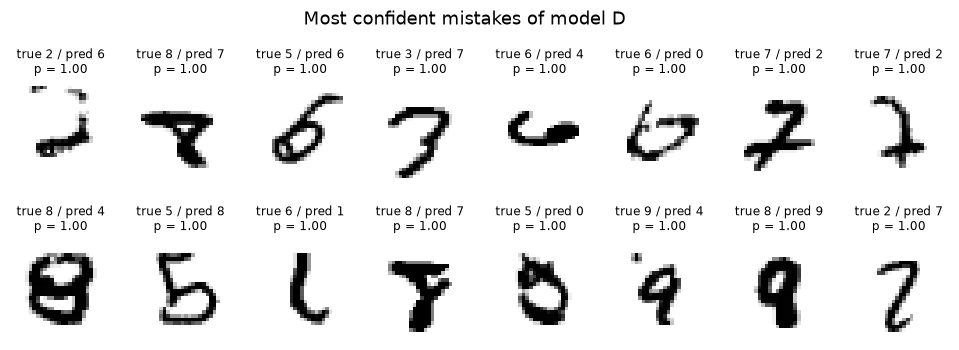

In [18]:
P_test = softmax(model_D.forward(X_test)[0])                  # class probabilities
wrong = np.flatnonzero(pred_D != true_D)
order = wrong[np.argsort(-P_test[wrong, pred_D[wrong]])]      # most confident wrong answers first
print(f"{len(wrong)} misclassified test images")

fig, axes = plt.subplots(2, 8, figsize=(11, 3.4))
for ax, i in zip(axes.flat, order[:16]):
    ax.imshow(test_images_raw[i], cmap="gray_r"); ax.axis("off")
    ax.set_title(f"true {true_D[i]} / pred {pred_D[i]}\np = {P_test[i, pred_D[i]]:.2f}", fontsize=8)
fig.suptitle("Most confident mistakes of model D", y=1.03); plt.show()

### 11.3 What did the first layer learn?

Each column of $W^{(1)}$ has 784 entries – one per pixel – and can be displayed as a $28\times28$ image. Red pixels
increase, blue pixels decrease the pre-activation of that hidden unit. The structured patterns in the centre are
stroke and blob detectors. Pixels near the border are (almost) always 0 in MNIST; since
$\partial\mathcal L/\partial W^{(1)} = X^\top\delta^{(1)}$, their weights receive (almost) no gradient and keep their small random
initial values – the faint, structureless frame around each pattern.

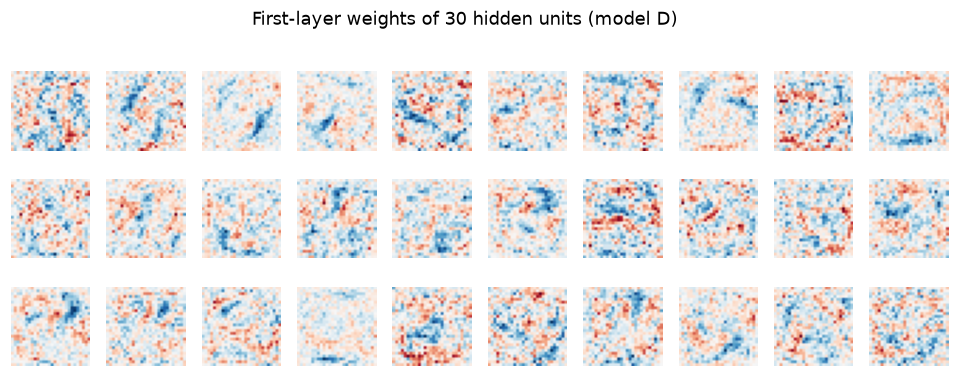

In [19]:
W1 = model_D.W[0]                                            # (784, 256)
fig, axes = plt.subplots(3, 10, figsize=(11, 3.6))
for ax, j in zip(axes.flat, range(30)):
    w = W1[:, j].reshape(28, 28)
    lim = np.abs(w).max()
    ax.imshow(w, cmap="RdBu_r", vmin=-lim, vmax=lim); ax.axis("off")
fig.suptitle("First-layer weights of 30 hidden units (model D)", y=1.02); plt.show()

In [20]:
print(f"Total notebook run time: {(time.time() - T_NOTEBOOK) / 60:.1f} min")

Total notebook run time: 1.8 min


## 12. Summary, exercises and references

### 12.1 What we have seen

1. An MLP is a chain of matrix multiplications and element-wise non-linearities; its gradients follow from the
   four back-propagation equations of Section 2.6, verified numerically in Section 6.
2. **Stochastic** gradient descent (one image per step) works but is slow; **mini-batch** descent with one update
   per batch is the correct and efficient generalisation (the "naive" version of `chapter_8_2` applied each batch
   gradient $B$ times).
3. With 1000 training images the network overfits; **dropout** reduces the gap between training and test accuracy.
   Whether it improves the *best* test accuracy must be judged over several seeds and with a validation set
   (Experiment C), not from a single run.
4. More data, He initialisation, biases, softmax + cross-entropy and Adam (Experiment D) raise the test accuracy
   to the level typical of MLPs on MNIST.
5. The twin notebook in PyTorch implements the same equations; compare the numbers.

### 12.2 Exercises

| # | Change | Question |
|---|---|---|
| 1 | Experiment A: `lr = 0.05` and `lr = 0.0005` | How do speed and stability change? |
| 2 | Experiment B: `batch_size = 10, 1000` with $\eta$ scaled as in 2.7 | Is the result the same per epoch? per second? |
| 3 | Experiment C: `dropout_p = 0.2, 0.8` | Where is the best trade-off for 800 images? |
| 4 | Experiment D: MSE instead of cross-entropy | How much accuracy is lost? |
| 5 | Experiment D: `hidden = [512, 256, 128]` | Does depth help an MLP on MNIST? |
| 6 | Experiment D: SGD + momentum instead of Adam | Which learning rate is needed? |
| 7 | Section 6: make an error in the back-propagation on purpose | Does the gradient check detect it? |

### 12.3 References

* A. W. Trask, *Grokking Deep Learning*, Manning, 2019 – ch. 4–6 (gradient descent, back-propagation), ch. 8 (overfitting, dropout, batch gradient descent).
* I. Goodfellow, Y. Bengio, A. Courville, *Deep Learning*, MIT Press – ch. 6 (deep feed-forward networks, 6.5 back-propagation),
  ch. 7.12 (dropout), ch. 8.3–8.5 (SGD, momentum, Adam), ch. 8.4 (initialisation).
* Y. LeCun, L. Bottou, Y. Bengio, P. Haffner, "Gradient-based learning applied to document recognition", *Proc. IEEE* 86 (1998) – MNIST.
* N. Srivastava et al., "Dropout: a simple way to prevent neural networks from overfitting", *JMLR* 15 (2014).
* K. He et al., "Delving deep into rectifiers", *ICCV* 2015 – He initialisation.
* D. P. Kingma, J. Ba, "Adam: a method for stochastic optimization", *ICLR* 2015.